In [1]:
import sys
sys.path.append("../src")
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from features import make_features, FEATURES
from evaluation import time_split

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss_manual(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(sigmoid(0), sigmoid(2), sigmoid(-2))
p = 0.9
print("loss if truth=1:", -np.log(p), "| loss if truth=0:", -np.log(1 - p))


0.5 0.8807970779778823 0.11920292202211755
loss if truth=1: 0.10536051565782628 | loss if truth=0: 2.302585092994046


In [2]:
def fit_logreg_gd(X, y, lr=0.1, n_iter=20000):
    n, k = X.shape
    w, b = np.zeros(k), 0.0
    history = []
    for i in range(n_iter):
        p = sigmoid(X @ w + b)                  # predicted probabilities
        w -= lr * (X.T @ (p - y) / n)           # gradient of log-loss for weights
        b -= lr * np.mean(p - y)                # gradient for the intercept
        if i % 200 == 0:
            history.append(log_loss_manual(y, p))
    return w, b, history


first loss (should be about 0.6931): 0.6931
final loss: 0.6888


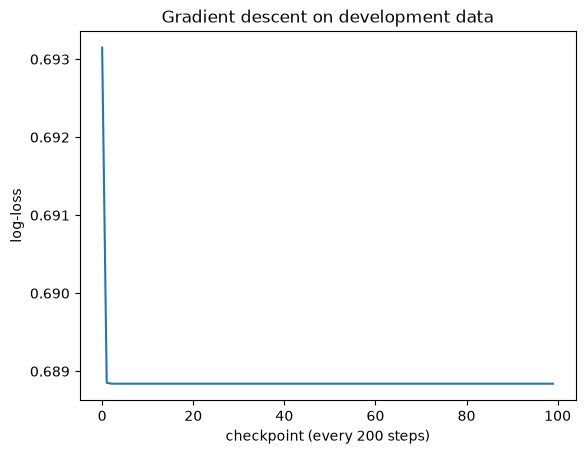

In [3]:
PRICE_COLS = ["Open", "High", "Low", "Close", "Volume"]
df = pd.read_csv("../data/LUCK_target.csv", index_col="Date", parse_dates=True)
data = make_features(df[PRICE_COLS]).join(df["target"])
dev, _ = time_split(data)
dev = dev.dropna()

X_raw = dev[FEATURES]
y = dev["target"].to_numpy()
mu, sd = X_raw.mean(), X_raw.std(ddof=0)
X = ((X_raw - mu) / sd).to_numpy()

w, b, history = fit_logreg_gd(X, y)
print("first loss (should be about 0.6931):", round(history[0], 4))
print("final loss:", round(history[-1], 4))

plt.plot(history)
plt.xlabel("checkpoint (every 200 steps)")
plt.ylabel("log-loss")
plt.title("Gradient descent on development data")
plt.show()


### Training Logistic Regression Using Gradient Descent

This cell trains our own logistic regression model on the LUCK development dataset using the gradient descent implementation.

**Steps performed:**

1. **Select price columns:** Load the Open, High, Low, Close and Volume data.
2. **Generate features:** Calculate the six features using `make_features()` and attach the actual `target` (UP = 1, DOWN = 0).
3. **Separate development data:** Use `time_split()` to exclude the test dataset from training.
4. **Remove missing values:** Use `dropna()` to remove rows where features cannot be calculated due to insufficient historical data.
5. **Separate inputs and targets:**
   - `X_raw`: The six input features.
   - `y`: The actual UP/DOWN outcomes.
6. **Standardise features:** Calculate the mean (`mu`) and standard deviation (`sd`) of each feature, then transform the values using:

   \[
   z = \frac{x-\mu}{sd}
   \]

   This puts the features on comparable numerical scales, helping gradient descent optimise the model more effectively.
7. **Train the model:** Call `fit_logreg_gd()` to learn the feature weights (`w`) and intercept (`b`) by repeatedly adjusting them to minimise log loss.
8. **Track training progress:** Record the log loss every 200 iterations and plot it to observe how the model learns.

**Results and interpretation:**

- Initial log loss: **0.6931**. The model initially predicts a 50% probability of UP for every observation because all weights and the intercept start at zero.
- Final recorded log loss: **0.6888**.
- The graph shows a sharp decrease in loss during the first 200 iterations, followed by an almost flat line.

This indicates that most of the reduction in training loss happened early, with very little improvement during the remaining iterations.

**Important:** A decreasing training loss indicates that the optimisation is improving the model's fit to the development data. It does not establish that the model can accurately predict unseen stock movements. We will evaluate that separately using validation and test data.

In [4]:
sk = LogisticRegression(C=1e6, max_iter=5000).fit(X, y)

cmp = pd.DataFrame({"scratch": w, "sklearn": sk.coef_[0]}, index=FEATURES)
cmp.loc["intercept"] = [b, sk.intercept_[0]]
print(cmp.round(4))
print("max abs difference:", np.abs(cmp["scratch"] - cmp["sklearn"]).max().round(5))



           scratch  sklearn
ret_1       0.1318   0.1318
ret_5       0.0159   0.0159
vol_10     -0.0187  -0.0187
vol_chg     0.0617   0.0617
hl_range    0.0184   0.0183
ma_dist    -0.0865  -0.0865
intercept  -0.1059  -0.1059
max abs difference: 8e-05


### Comparing Custom Gradient Descent with Scikit-learn

This experiment checks whether my manually implemented logistic regression produces similar parameters to Scikit-learn's implementation.

- Trained Scikit-learn's `LogisticRegression` using the same standardised data.
- Set `C=1e6` to make regularisation extremely weak, allowing a fair comparison with my custom implementation, which has no regularisation.
- Compared the learned weights and intercepts.
- Calculated the maximum absolute difference between corresponding parameters.

**Result:** The maximum difference was `0.00008`, meaning both implementations produced almost identical parameters.

**Conclusion:** This provides strong evidence that my custom gradient descent implementation correctly calculates and updates the weights and intercept. It verifies the implementation, not the model's predictive performance.